# Análisis de sentimientos

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Este cuaderno contiene una copia completa de `sentimientos.py` y sus salidas reales. Ejecuta todas las celdas en orden, desde esta carpeta. La explicación y el análisis están en [README.md](README.md). Los archivos de entrada están en `datos/` cuando corresponda.

El código fuente principal se conserva en el archivo `.py`; `herramientas/generar_cuadernos.py` regenera y ejecuta este cuaderno después de cambiarlo.

In [1]:
import os, sys
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
# Las rutas y argumentos equivalen a ejecutar el script desde esta carpeta.
__file__ = str(Path.cwd() / 'sentimientos.py')
sys.argv = [__file__]

In [2]:
"""Clasificador de sentimientos didáctico basado en un léxico, sin modelo entrenado."""
import argparse
import csv
import json
import re
import unicodedata
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

POSITIVAS={"feliz","alegre","contento","excelente","increible","genial","encanto","encanta","bueno","buena","maravilloso","divertido","divertida","amo","ame","recomiendo","espectacular","bien"}
NEGATIVAS={"triste","mal","malo","mala","pesimo","horrible","aburrido","aburrida","decepcionante","odio","odie","feo","fea","terrible","deprimido","enojado"}


def tokenizar(texto):
    normal="".join(c for c in unicodedata.normalize("NFD",texto.lower()) if unicodedata.category(c)!="Mn")
    return re.findall(r"[a-zñ]+|[.,;!?]",normal)


def analizar(texto):
    tokens=tokenizar(texto); puntos=0; explicacion=[]; negacion=0; peso=1
    for token in tokens:
        if token in ".,;!?": negacion=0; continue
        if token in {"pero","aunque"}: peso=2; negacion=0; continue
        if token in {"no","nunca","jamas"}: negacion=2; continue
        valor=1 if token in POSITIVAS else -1 if token in NEGATIVAS else 0
        if valor:
            aporte=valor*peso*(-1 if negacion>0 else 1)
            puntos+=aporte; explicacion.append({"token":token,"aporte":aporte})
        negacion=max(0,negacion-1)
    return {"texto":texto,"sentimiento":"positivo" if puntos>0 else "negativo" if puntos<0 else "neutral","puntaje":puntos,"coincidencias":explicacion}


def main():
    p=argparse.ArgumentParser(); p.add_argument("--texto"); args=p.parse_args()
    if args.texto: print(json.dumps(analizar(args.texto),ensure_ascii=False,indent=2)); return
    casos=["El taller fue excelente y divertido.","La experiencia fue horrible y aburrida.","La clase empieza a las ocho.","No es bueno.","No es malo.","Bueno, pero aburrido.","Fue increíble, ¡lo recomiendo!","Sí, excelente... otra falla del sistema."]
    resultados=[analizar(t) for t in casos]
    out=Path(__file__).parent/"resultados"; out.mkdir(exist_ok=True)
    for r in resultados: print(f"{r['sentimiento']:8} ({r['puntaje']:+d}): {r['texto']}")
    assert analizar("No es bueno")["sentimiento"]=="negativo"
    assert analizar("No es malo")["sentimiento"]=="positivo"
    (out/"analisis.json").write_text(json.dumps(resultados,ensure_ascii=False,indent=2),encoding="utf-8")
    with (out/"analisis.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.writer(f); w.writerow(["texto","sentimiento","puntaje"]); w.writerows([[r["texto"],r["sentimiento"],r["puntaje"]] for r in resultados])
    fig,ax=plt.subplots(figsize=(10,4)); valores=[r["puntaje"] for r in resultados]
    ax.bar(range(1,len(valores)+1),valores,color=["#21866a" if v>0 else "#c94f56" if v<0 else "#758091" for v in valores]); ax.axhline(0,color="black",linewidth=.7)
    ax.set(xlabel="Número de frase (ver analisis.csv)",ylabel="Puntaje léxico",title="Sentimientos por reglas: casos de prueba")
    fig.tight_layout(); fig.savefig(out/"sentimientos.png",dpi=150); plt.close(fig)
    print("Limitación observada: el sarcasmo de la última frase se clasifica como positivo.")


if __name__=="__main__": main()


positivo (+2): El taller fue excelente y divertido.
negativo (-2): La experiencia fue horrible y aburrida.
neutral  (+0): La clase empieza a las ocho.
negativo (-1): No es bueno.
positivo (+1): No es malo.
negativo (-1): Bueno, pero aburrido.
positivo (+2): Fue increíble, ¡lo recomiendo!
positivo (+1): Sí, excelente... otra falla del sistema.
Limitación observada: el sarcasmo de la última frase se clasifica como positivo.


## Imágenes producidas por esta ejecución

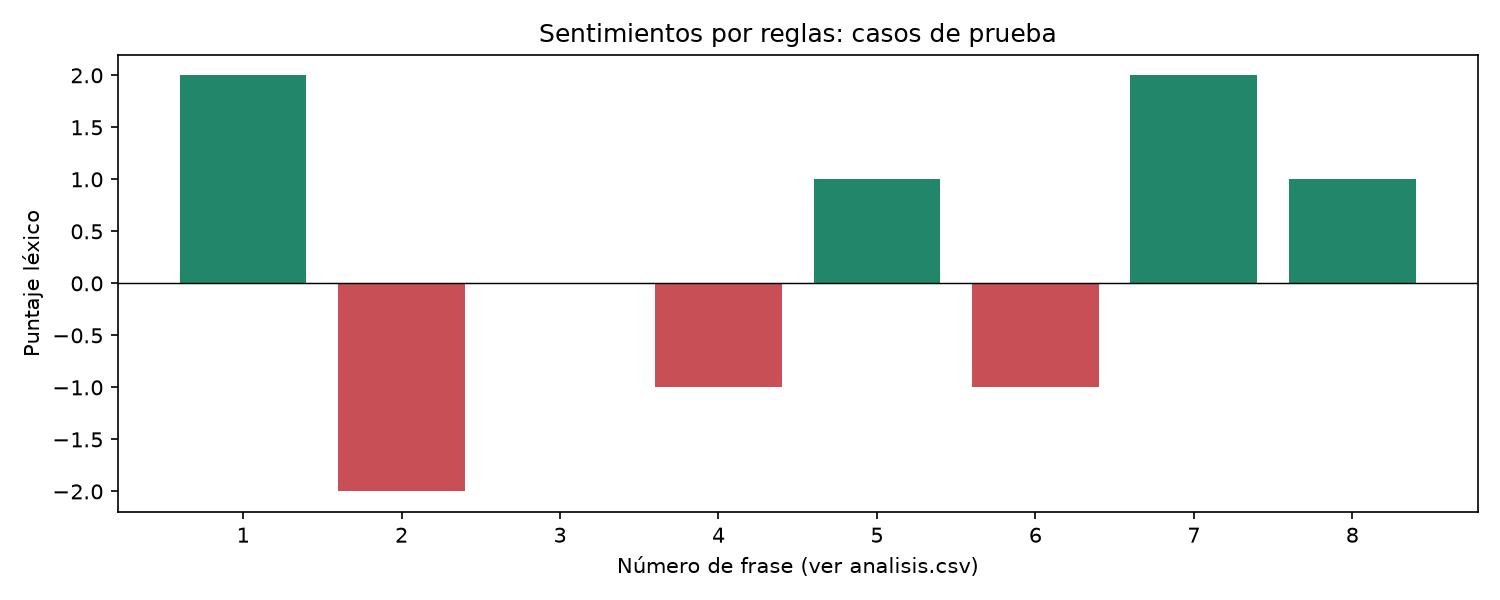

In [3]:
from IPython.display import display, Image
display(Image(filename='resultados/sentimientos.png'))